<a href="https://colab.research.google.com/github/sahiljangra12/Academic-Projects/blob/main/04-speech-signal-processing/speech_signal_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Speech Signal Processing

Transcribe a short recording in English and Hindi, then look at its acoustic structure: waveform, spectrogram and formants.


## Setup


In [ ]:
%pip install -q SpeechRecognition librosa matplotlib numpy praat-parselmouth


In [ ]:
# Upload a short speech recording (WAV). Rename it or change AUDIO_FILE below.
from google.colab import files
uploaded = files.upload()

AUDIO_FILE = "NLP Assignment.wav"


## 1. Speech-to-text


In [5]:
import speech_recognition as sr


In [8]:
r = sr.Recognizer()
with sr.AudioFile(AUDIO_FILE) as source:
    audio = r.record(source)


In [9]:
try:
    text = r.recognize_google(audio)
    print("Recognized Text:", text)
except sr.UnknownValueError:
    print("Could not understand audio")
except sr.RequestError as e:
    print("Service error:", e)


Recognized Text: hello hello hello hello hello hello hello hello hello hello hello hello hello hello


In [10]:
text = r.recognize_google(audio, language="hi-IN")
print(text)


हेलो हेलो हेलो हेलो हेलो हेलो हेलो हेलो हेलो हेलो क्या हो गया भाई क्या हाल है


## 2. Signal basics


In [14]:
import librosa
import numpy as np

y, sr_audio = librosa.load(AUDIO_FILE, sr=None)

print("Sampling Rate:", sr_audio)
print("Number of Samples:", len(y))


Sampling Rate: 48000
Number of Samples: 717824


## 3. Waveform


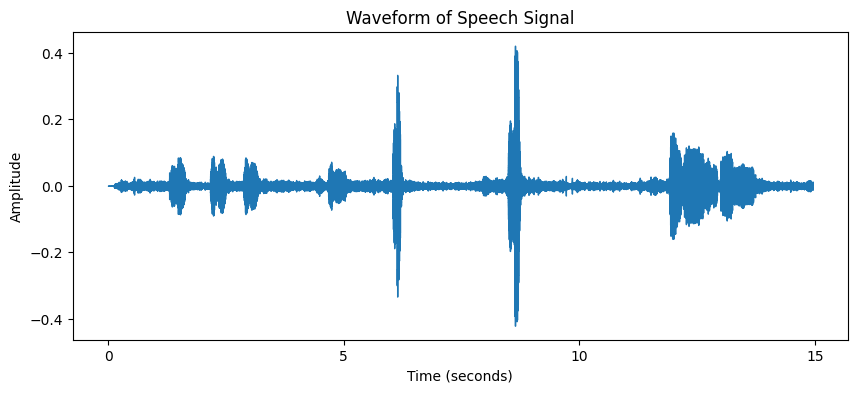

In [15]:
import librosa.display
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
librosa.display.waveshow(y, sr=sr_audio)
plt.title("Waveform of Speech Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()


## 4. Spectrogram

Short-time Fourier transform, shown in decibels on a log-frequency axis.


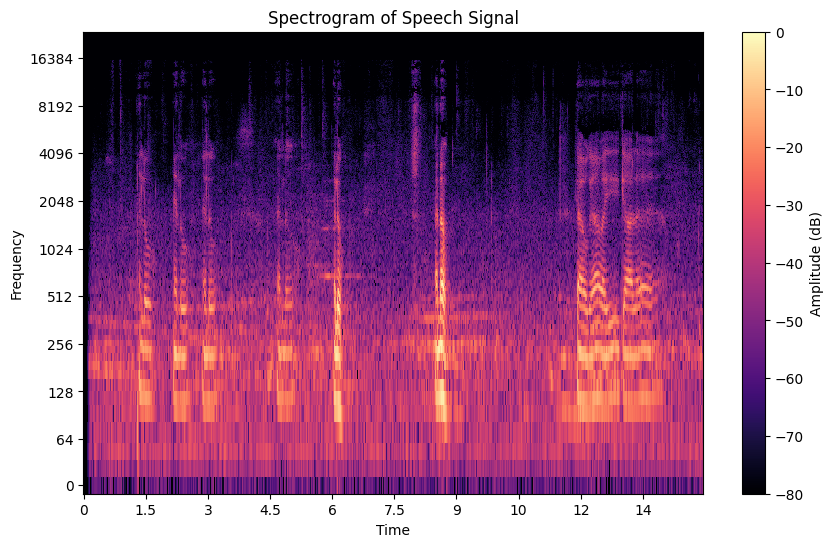

In [16]:
S = np.abs(librosa.stft(y))
S_db = librosa.amplitude_to_db(S, ref=np.max)

plt.figure(figsize=(10,6))
librosa.display.specshow(
    S_db,
    sr=sr_audio,
    x_axis='time',
    y_axis='log'
)
plt.colorbar(label="Amplitude (dB)")
plt.title("Spectrogram of Speech Signal")
plt.xlabel("Time")
plt.ylabel("Frequency")
plt.show()


## 5. Formants

First three formants (F1–F3) tracked with Praat's Burg method.


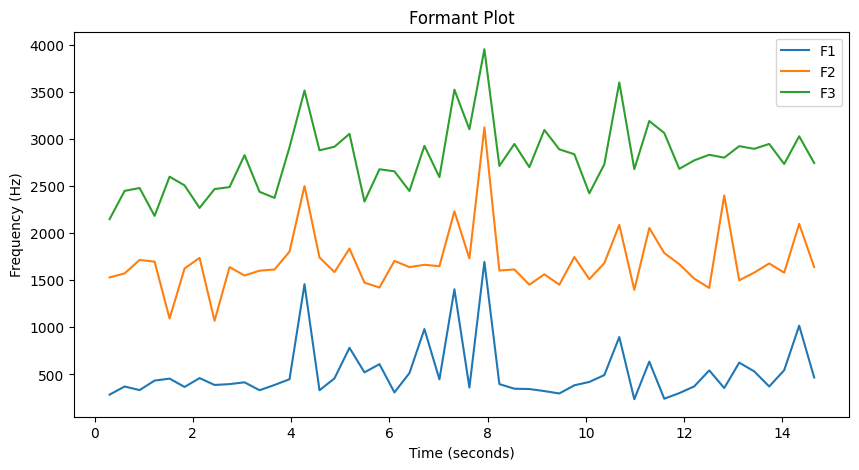

In [17]:
import parselmouth

sound = parselmouth.Sound(AUDIO_FILE)
formant = sound.to_formant_burg()

times = np.linspace(0, sound.duration, 50)

f1 = [formant.get_value_at_time(1, t) for t in times]
f2 = [formant.get_value_at_time(2, t) for t in times]
f3 = [formant.get_value_at_time(3, t) for t in times]

plt.figure(figsize=(10,5))
plt.plot(times, f1, label="F1")
plt.plot(times, f2, label="F2")
plt.plot(times, f3, label="F3")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.title("Formant Plot")
plt.legend()
plt.show()